<a href="https://colab.research.google.com/github/ctobar96/ClasificacionTerreno/blob/main/notebooks/03_transfer_learning_efficientnet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Fase 2: Transfer Learning - Extracción de Características (*Feature Extraction*)

En esta etapa del proyecto, evolucionamos desde la arquitectura CNN construida desde cero (que estableció un sólido *baseline* del ~93% de exactitud) hacia el uso de **Transfer Learning** mediante el modelo preentrenado **EfficientNetB0**.

El objetivo principal de esta fase es superar el cuello de botella visual detectado en la evaluación del modelo anterior: la dificultad algorítmica para diferenciar microtexturas complejas y de grano fino, particularmente entre clases agrícolas y naturales (como *HerbaceousVegetation*, *PermanentCrop* y *Highway*).

**Fundamentos Técnicos de la Implementación:**

1. **Transferencia de Conocimiento:** Se importa la arquitectura base de EfficientNetB0 junto con sus pesos preentrenados en ImageNet. Esta red ya posee filtros matemáticos altamente optimizados para detectar formas, bordes y jerarquías de texturas de gran complejidad.
2. **Congelamiento de Pesos (*Freezing*):** Se bloquea la actualización de gradientes en las capas convolucionales base (`trainable = False`). Esto transforma a EfficientNetB0 en un "extractor de características puro", garantizando que su conocimiento previo no se destruya por los ajustes bruscos de las primeras épocas de entrenamiento.
3. **Acoplamiento de la Cabeza Clasificadora (Top Layers):** Se elimina la capa de salida original de 1000 clases (`include_top = False`) y se sustituye por una nueva red neuronal densa customizada (con regularización *Dropout* y *Batch Normalization*).

Durante esta etapa, **solo se entrenará la nueva cabeza clasificadora**. Su única tarea será aprender a mapear los mapas de características genéricos extraídos por EfficientNet hacia las 10 categorías específicas del dominio satelital EuroSAT, buscando alcanzar o superar el 95% de exactitud.

In [4]:
# ==============================================================================
# 1. BIBLIOTECA ESTÁNDAR DE PYTHON
# ==============================================================================
import gc
import json
import os

# ==============================================================================
# 2. LIBRERÍAS DE TERCEROS (CIENCIA DE DATOS Y VISUALIZACIÓN)
# ==============================================================================
import matplotlib.pyplot as plt
import tensorflow as tf

# ==============================================================================
# 3. COMPONENTES ESPECÍFICOS DE TENSORFLOW / KERAS
# ==============================================================================
from tensorflow.keras import Sequential
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.layers import (
    BatchNormalization,
    Dense,
    Dropout,
    GlobalAveragePooling2D
)
from tensorflow.keras.optimizers import Adam

print("✅ Todas las librerías han sido importadas y ordenadas exitosamente sin duplicados.")

✅ Todas las librerías han sido importadas y ordenadas exitosamente sin duplicados.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
# CARGAR EL DATASET
BASE_DIR = '/content/drive/MyDrive/ClasificacionTerreno'
ruta_guardado = f"{BASE_DIR}/data/raw_splits"

# Cargar los datasets
train_ds = tf.data.Dataset.load(f"{ruta_guardado}/train")
val_ds = tf.data.Dataset.load(f"{ruta_guardado}/val")
test_ds = tf.data.Dataset.load(f"{ruta_guardado}/test")

In [9]:
# 1. Creamos el adaptador oficial de preprocesamiento para EfficientNetB0
def adaptador_efnet_oficial(image, label):
    image = tf.cast(image, tf.float32)
    image = tf.image.resize(image, [128, 128])
    image = preprocess_input(image)
    return image, label

# 2. NUEVO: Creamos una función de Data Augmentation que NO recorte a 1.0
def augment_image_tl(imagen, etiqueta):
    imagen = tf.image.random_flip_left_right(imagen)
    imagen = tf.image.random_flip_up_down(imagen)
    imagen = tf.image.random_brightness(imagen, max_delta=0.1)
    imagen = tf.image.random_contrast(imagen, lower=0.9, upper=1.1)
    # Asegurar que los valores sigan en el rango esperado por EfficientNet [0, 255]
    imagen = tf.clip_by_value(imagen, 0.0, 255.0)
    return imagen, etiqueta

# 3. Re-construir los datasets de TL
BATCH_SIZE = 32

print("Preparando datasets correctos para Transfer Learning con EfficientNetB0...")
train_dataset_tl = train_ds \
    .map(adaptador_efnet_oficial, num_parallel_calls=2) \
    .map(augment_image_tl, num_parallel_calls=2) \
    .shuffle(500) \
    .batch(BATCH_SIZE) \
    .prefetch(2)

val_dataset_tl = val_ds \
    .map(adaptador_efnet_oficial, num_parallel_calls=2) \
    .batch(BATCH_SIZE) \
    .prefetch(2)

test_dataset_tl = test_ds \
    .map(adaptador_efnet_oficial, num_parallel_calls=2) \
    .batch(BATCH_SIZE) \
    .prefetch(2)

print("¡Datasets de Transfer Learning listos y optimizados!")

Preparando datasets correctos para Transfer Learning con EfficientNetB0...
¡Datasets de Transfer Learning listos y optimizados!


### Paso Siguiente:
Una vez ejecutada la celda anterior para corregir el preprocesamiento, debes volver a compilar tu modelo de Transfer Learning ejecutando la celda `Yvy3u15Is4Qv` y entrenar nuevamente usando la celda `Sn1ExRsuw7-G`. ¡Verás cómo la precisión de validación sube inmediatamente por encima del 90% desde la primera época!

In [10]:
# 1. Cargar el modelo base preentrenado (EfficientNetB0) sin la capa de salida
base_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(128, 128, 3))

# 2. FEATURE EXTRACTION: Congelar los pesos preentrenados
# Esto asegura que los filtros matemáticos originales no se destruyan
base_model.trainable = False

# 3. Construir la nueva cabeza de clasificación
model_tl = Sequential()
model_tl.add(base_model) # Usamos EfficientNetB0 en lugar de modelo_recuperado
model_tl.add(GlobalAveragePooling2D())

# Capa densa intermedia para adaptar las características a tu dominio satelital
model_tl.add(Dense(128, activation='relu'))
model_tl.add(BatchNormalization())
model_tl.add(Dropout(0.3)) # Regularización moderada para la nueva capa

# Capa de salida estricta para las 10 clases de EuroSAT
model_tl.add(Dense(10, activation='softmax'))

# 4. Compilar el nuevo modelo
# Usamos un learning rate estándar (0.001) ideal para entrenar capas nuevas desde cero
model_tl.compile(optimizer=Adam(learning_rate=0.001),
                 loss='sparse_categorical_crossentropy',
                 metrics=['accuracy'])

# Imprimir el resumen para verificar los parámetros entrenables
model_tl.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,215,341 (16.08 MB)

 Trainable params: 165,514 (646.54 KB)

 Non-trainable params: 4,049,827 (15.45 MB)

La siguiente celda se encarga de definir y cargar en la memoria de Python tres herramientas de control automáticas (`llamadas Callbacks`) que supervisan el entrenamiento del modelo de Transfer Learning.

Esto es exactamente lo que hace cada una:

1. `LimpiezaMemoria (limpieza_cb)`: Cada vez que termina una época de entrenamiento, obliga a Python a recolectar basura y liberar memoria RAM residual (`gc.collect()`). Esto es clave en Google Colab para evitar que la sesión se caiga por falta de memoria debido al procesamiento de imágenes.

2. `EarlyStopping (early_stop)`: Monitorea la pérdida en el conjunto de validación (`val_loss`). Si la pérdida deja de mejorar durante 8 épocas seguidas, detiene automáticamente el entrenamiento para evitar que el modelo se sobreajuste (aprenda de memoria) y restaura los pesos de la época que haya tenido el mejor rendimiento absoluto.

3. `ReduceLROnPlateau (reduce_lr)`: Si ve que el entrenamiento se estanca y la pérdida de validación no mejora durante 3 épocas seguidas, reduce a la mitad (factor=0.5) la velocidad con la que el modelo aprende (el Learning Rate). Esto ayuda a que el optimizador dé pasos más pequeños y precisos para encontrar el punto óptimo de exactitud.

In [11]:
# 1. Redefinir Limpieza de Memoria
class LimpiezaMemoria(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        gc.collect()

limpieza_cb = LimpiezaMemoria()

# 2. Redefinir Parada Temprana
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True
)

# 3. Redefinir Reductor de Tasa de Aprendizaje
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

print("✅ Callbacks (limpieza_cb, early_stop y reduce_lr) cargados en memoria exitosamente.")
print("👉 Ahora puedes ejecutar la celda de entrenamiento (history_tl = ...).")

✅ Callbacks (limpieza_cb, early_stop y reduce_lr) cargados en memoria exitosamente.
👉 Ahora puedes ejecutar la celda de entrenamiento (history_tl = ...).


In [13]:
# 1. ACTUALIZACIÓN CRÍTICA: Nueva ruta para proteger el modelo del 93% (Baseline)
ruta_modelo_tl = f'{BASE_DIR}/models/fine_tuned/modelo_efnetb0_fe_eurosat.keras'

checkpoint_tl = ModelCheckpoint(
    filepath=ruta_modelo_tl,
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

# 2. Configuración de épocas
# El Feature Extraction suele converger un poco más rápido, pero mantenemos
# un límite alto apoyándonos en el EarlyStopping
EPOCHS_TL = 50

print("\033[1m--- INICIANDO FASE 2: FEATURE EXTRACTION CON EFFICIENTNETB0 ---\033[0m")

# 3. Iniciar el entrenamiento de la cabeza clasificadora
# Nota que pasamos 'model_tl' y usamos la nueva variable 'history_tl'
history_tl = model_tl.fit(
    train_dataset_tl,
    validation_data=val_dataset_tl,
    epochs=EPOCHS_TL,
    verbose=1,
    # Reutilizamos los callbacks genéricos y agregamos el NUEVO checkpoint
    callbacks=[early_stop, reduce_lr, checkpoint_tl, limpieza_cb]
)

# 4. Evaluación estrictamente en el conjunto de prueba aislado
print("\n\033[1m--- EVALUACIÓN FINAL DEL MODELO TL ---\033[0m")
score_tl = model_tl.evaluate(test_dataset_tl, verbose=0)
print('Test loss (Transfer Learning): ', score_tl[0])
print('Test accuracy (Transfer Learning): ', score_tl[1])

--- INICIANDO FASE 2: FEATURE EXTRACTION CON EFFICIENTNETB0 ---
Epoch 1/50
591/591 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.8262 - loss: 0.5411
Epoch 1: val_accuracy improved from None to 0.93877, saving model to /content/drive/MyDrive/ClasificacionTerreno/models/fine_tuned/modelo_efnetb0_fe_eurosat.keras

Epoch 1: finished saving model to /content/drive/MyDrive/ClasificacionTerreno/models/fine_tuned/modelo_efnetb0_fe_eurosat.keras
591/591 ━━━━━━━━━━━━━━━━━━━━ 52s 88ms/step - accuracy: 0.8800 - loss: 0.3694 - val_accuracy: 0.9388 - val_loss: 0.1773 - learning_rate: 0.0010
Epoch 2/50
590/591 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9208 - loss: 0.2424
Epoch 2: val_accuracy improved from 0.93877 to 0.94222, saving model to /content/drive/MyDrive/ClasificacionTerreno/models/fine_tuned/modelo_efnetb0_fe_eurosat.keras

Epoch 2: finished saving model to /content/drive/MyDrive/ClasificacionTerreno/models/fine_tuned/modelo_efnetb0_fe_eurosat.keras
591/591 ━━━━━━━━━━━━━━━━━━━━ 15s

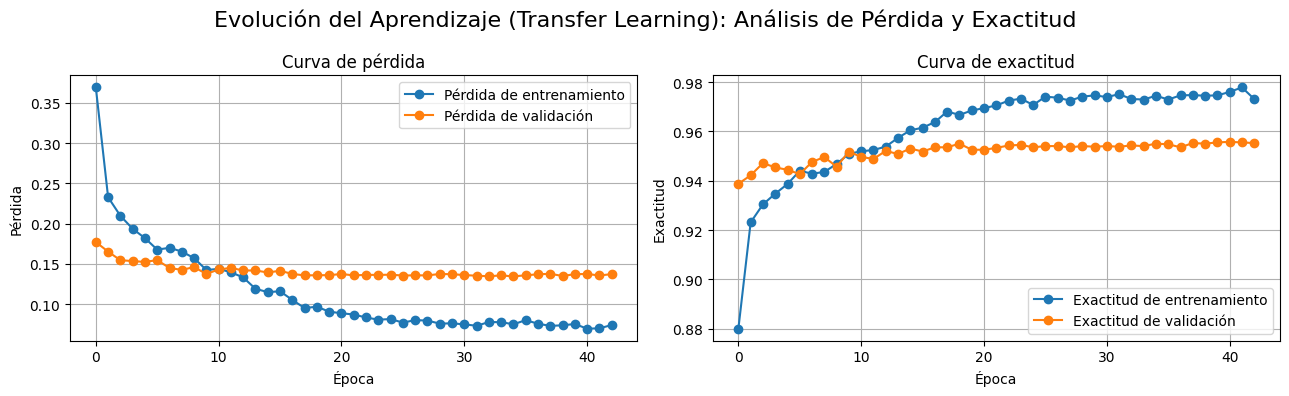

In [17]:
# Crear la figura y los subgráficos
fig, axs = plt.subplots(1, 2, figsize=(13, 4))

# Título general de la figura
fig.suptitle('Evolución del Aprendizaje (Transfer Learning): Análisis de Pérdida y Exactitud', fontsize=16)

# Primer gráfico: Pérdida
axs[0].plot(history_tl.history['loss'], 'o-', label='Pérdida de entrenamiento')
axs[0].plot(history_tl.history['val_loss'], 'o-', label='Pérdida de validación')
axs[0].set_xlabel('Época')
axs[0].set_ylabel('Pérdida')
axs[0].set_title('Curva de pérdida')
axs[0].legend()
axs[0].grid(True)

# Segundo gráfico: Exactitud
axs[1].plot(history_tl.history['accuracy'], 'o-', label='Exactitud de entrenamiento')
axs[1].plot(history_tl.history['val_accuracy'], 'o-', label='Exactitud de validación')
axs[1].set_xlabel('Época')
axs[1].set_ylabel('Exactitud')
axs[1].set_title('Curva de exactitud')
axs[1].legend()
axs[1].grid(True)

plt.tight_layout()
plt.show()

### **GUARDADO DE RESULTADOS E HISTORIAL**
Esta sección guarda las métricas de entrenamiento a lo largo de las épocas (historial) en archivos JSON para ambos modelos, además de un archivo de texto con un resumen de los resultados en el conjunto de prueba (Test). Esto facilita la comparación futura de arquitecturas.

In [14]:
# Función auxiliar para exportar el historial a JSON
def guardar_historial(historial, nombre_archivo):
    # Extraer el diccionario de métricas
    historial_dict = historial.history

    # Convertir los valores a float estándar de Python para que JSON lo pueda serializar
    for key in historial_dict.keys():
        historial_dict[key] = [float(val) for val in historial_dict[key]]

    ruta_completa = os.path.join(BASE_DIR, 'logs/histories', nombre_archivo)

    with open(ruta_completa, 'w') as f:
        json.dump(historial_dict, f, indent=4)
    print(f"✅ Historial guardado en: {ruta_completa}")

# 1. Guardar historial del modelo CNN base
if 'history' in globals():
    guardar_historial(history, 'historial_cnn_base.json')

# 2. Guardar historial del modelo Transfer Learning (EfficientNet)
if 'history_tl' in globals():
    guardar_historial(history_tl, 'historial_tl_efficientnet.json')

# 3. Guardar un resumen de los resultados de Test en un archivo de texto
ruta_resultados = os.path.join(BASE_DIR, 'reports/summaries/resultados_finales_test.txt')
with open(ruta_resultados, 'w') as f:
    f.write("--- RESULTADOS FINALES EN CONJUNTO DE PRUEBA (TEST) ---\n\n")
    if 'score' in globals():
        f.write(f"Modelo CNN Base (Entrenado desde cero):\n")
        f.write(f"- Loss: {score[0]:.4f}\n")
        f.write(f"- Accuracy: {score[1]:.4f}\n\n")

    if 'score_tl' in globals():
        f.write(f"Modelo Transfer Learning (EfficientNetB0):\n")
        f.write(f"- Loss: {score_tl[0]:.4f}\n")
        f.write(f"- Accuracy: {score_tl[1]:.4f}\n")

print(f"✅ Resumen de resultados (Test) guardado en: {ruta_resultados}")

✅ Historial guardado en: /content/drive/MyDrive/ClasificacionTerreno/logs/histories/historial_tl_efficientnet.json
✅ Resumen de resultados (Test) guardado en: /content/drive/MyDrive/ClasificacionTerreno/reports/summaries/resultados_finales_test.txt


In [28]:
print("📥 Cargando modelo CNN Base desde Drive...")
ruta_modelo_cnn_base = f'{BASE_DIR}/models/baselines/modelo_eurosat_optimizado.keras'
modelo_cnn_base = tf.keras.models.load_model(ruta_modelo_cnn_base)

print("\n⚙️ Preparando el dataset de prueba (64x64 y normalizado) y evaluando...")

# El CNN Base requiere imágenes de 64x64, así que debemos preprocesar test_ds
def preprocesar_cnn_base(image, label):
    image = tf.cast(image, tf.float32)
    image = tf.image.resize(image, [64, 64])
    # Aplicamos la normalización a [0,1] requerida por la CNN Base
    image = image / 255.0
    return image, label

test_ds_cnn_base = test_ds.map(preprocesar_cnn_base).batch(32).prefetch(tf.data.AUTOTUNE)

# Guardamos los resultados en la variable 'score' para que las tablas la detecten
score = modelo_cnn_base.evaluate(test_ds_cnn_base, verbose=1)

print("\n✅ ¡Métricas recuperadas con éxito!")
print(f"- Loss (CNN Base): {score[0]:.4f}")
print(f"- Accuracy (CNN Base): {score[1]:.4f}")

📥 Cargando modelo CNN Base desde Drive...

⚙️ Preparando el dataset de prueba (64x64 y normalizado) y evaluando...
127/127 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9304 - loss: 0.2096

✅ ¡Métricas recuperadas con éxito!
- Loss (CNN Base): 0.2096
- Accuracy (CNN Base): 0.9304


### **COMPARACIÓN DE MODELOS: CNN Base vs Transfer Learning**
A continuación, comparamos visualmente las curvas de validación (Exactitud y Pérdida) de ambos modelos entrenados, además de contrastar sus métricas finales en el conjunto de prueba no visto.

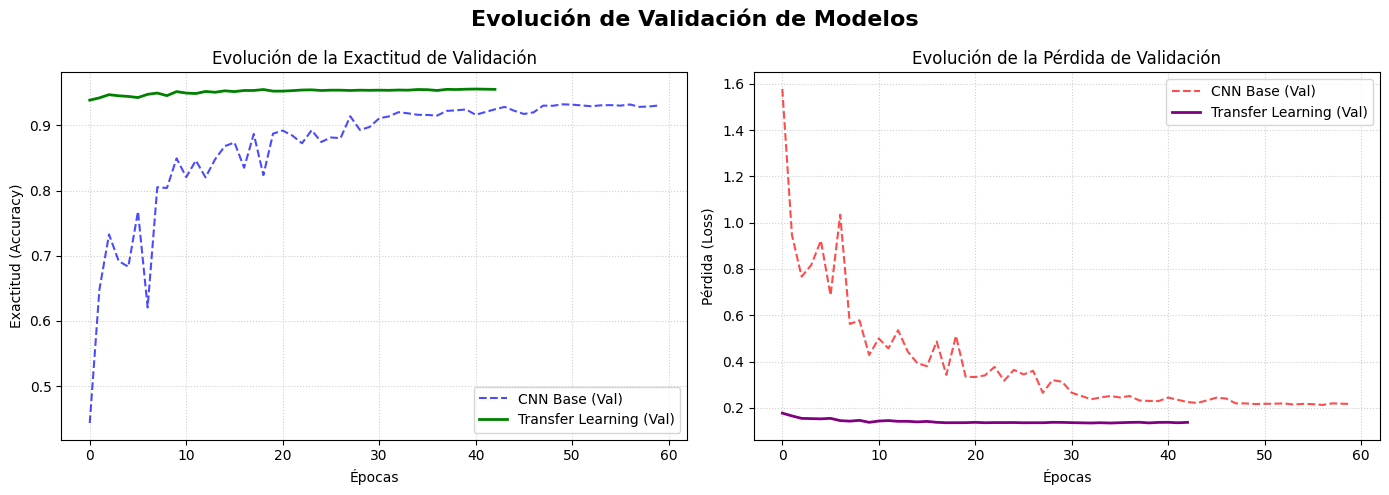


RESUMEN DE RESULTADOS EN CONJUNTO DE PRUEBA (TEST)
- Métrica -        | - CNN Base (Custom) -     | - Transfer Learning (EfficientNet) -
---------------------------------------------------------------------------
- Exactitud (Acc) - | 0.9304                    | 0.9573
- Pérdida (Loss)  - | 0.2096                    | 0.1391

💡 Conclusión: El modelo de Transfer Learning mejoró la exactitud final en +2.69 puntos porcentuales.


In [29]:
ruta_historial_cnn = os.path.join(BASE_DIR, 'logs/histories/historial_cnn_base.json')
ruta_historial_tl = os.path.join(BASE_DIR, 'logs/histories/historial_tl_efficientnet.json')

historial_cnn = None
historial_tl = None

# Intentar cargar desde los archivos JSON guardados en Drive si existen
if os.path.exists(ruta_historial_cnn):
    with open(ruta_historial_cnn, 'r') as f:
        historial_cnn = json.load(f)
else:
    print(f"⚠️ No se encontró el archivo: {ruta_historial_cnn}")

if os.path.exists(ruta_historial_tl):
    with open(ruta_historial_tl, 'r') as f:
        historial_tl = json.load(f)
else:
    print(f"⚠️ No se encontró el archivo: {ruta_historial_tl}")

# Crear la figura si hay al menos un historial
if historial_cnn or historial_tl:
    fig, axs = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle('Evolución de Validación de Modelos', fontsize=16, fontweight='bold')

    # Gráfico 1: Exactitud de Validación
    if historial_cnn:
        axs[0].plot(historial_cnn['val_accuracy'], label='CNN Base (Val)', color='blue', linestyle='--', alpha=0.7)
    if historial_tl:
        axs[0].plot(historial_tl['val_accuracy'], label='Transfer Learning (Val)', color='green', linewidth=2)
    axs[0].set_title('Evolución de la Exactitud de Validación')
    axs[0].set_xlabel('Épocas')
    axs[0].set_ylabel('Exactitud (Accuracy)')
    axs[0].legend()
    axs[0].grid(True, linestyle=':', alpha=0.6)

    # Gráfico 2: Pérdida de Validación
    if historial_cnn:
        axs[1].plot(historial_cnn['val_loss'], label='CNN Base (Val)', color='red', linestyle='--', alpha=0.7)
    if historial_tl:
        axs[1].plot(historial_tl['val_loss'], label='Transfer Learning (Val)', color='purple', linewidth=2)
    axs[1].set_title('Evolución de la Pérdida de Validación')
    axs[1].set_xlabel('Épocas')
    axs[1].set_ylabel('Pérdida (Loss)')
    axs[1].legend()
    axs[1].grid(True, linestyle=':', alpha=0.6)

    plt.tight_layout()
    plt.show()

# Tabla comparativa de resultados en Test
print("\n\033[1mRESUMEN DE RESULTADOS EN CONJUNTO DE PRUEBA (TEST)\033[0m")
print("=" * 75)
print(f"{'- Métrica -':<18} | {'- CNN Base (Custom) -':<25} | {'- Transfer Learning (EfficientNet) -'}")
print("-" * 75)

acc_cnn = score[1] if 'score' in globals() else None
loss_cnn = score[0] if 'score' in globals() else None

acc_tl = score_tl[1] if 'score_tl' in globals() else None
loss_tl = score_tl[0] if 'score_tl' in globals() else None

str_acc_cnn = f"{acc_cnn:<25.4f}" if acc_cnn is not None else f"{'N/A':<25}"
str_loss_cnn = f"{loss_cnn:<25.4f}" if loss_cnn is not None else f"{'N/A':<25}"

str_acc_tl = f"{acc_tl:.4f}" if acc_tl is not None else "N/A"
str_loss_tl = f"{loss_tl:.4f}" if loss_tl is not None else "N/A"

print(f"{'- Exactitud (Acc) -':<18} | {str_acc_cnn} | {str_acc_tl}")
print(f"{'- Pérdida (Loss)  -':<18} | {str_loss_cnn} | {str_loss_tl}")
print("=" * 75)

if acc_cnn is not None and acc_tl is not None:
    mejora_acc = (acc_tl - acc_cnn) * 100
    if mejora_acc > 0:
        print(f"\n💡 Conclusión: El modelo de Transfer Learning mejoró la exactitud final en +{mejora_acc:.2f} puntos porcentuales.")
    else:
        print(f"\n💡 Conclusión: El modelo base tuvo un mejor desempeño por {abs(mejora_acc):.2f} puntos porcentuales.")

### Fase 3: Fine-Tuning (Ajuste Fino)

En esta etapa descongelamos el modelo base (`EfficientNetB0`) para que sus filtros convolucionales puedan adaptarse sutilmente a las texturas específicas del dataset EuroSAT. Es **crucial** utilizar una tasa de aprendizaje (Learning Rate) muy baja (ej. `1e-5`) para no provocar cambios bruscos que destruyan los pesos preentrenados.

In [11]:
# 1. Descongelar el modelo base por completo
base_model.trainable = True

# 2. Recompilar el modelo.
# ¡CRÍTICO! Usar un Learning Rate muy bajo (1e-5 en lugar de 1e-3)
model_tl.compile(optimizer=Adam(learning_rate=1e-5),
                 loss='sparse_categorical_crossentropy',
                 metrics=['accuracy'])

print("✅ Modelo base descongelado y recompilado para Fine-Tuning.")
model_tl.summary()

✅ Modelo base descongelado y recompilado para Fine-Tuning.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,215,341 (16.08 MB)

 Trainable params: 4,173,062 (15.92 MB)

 Non-trainable params: 42,279 (165.16 KB)

In [16]:
# Nueva ruta para guardar el modelo de Fine-Tuning
ruta_modelo_ft = f'{BASE_DIR}/models/fine_tuned/modelo_efnetb0_finetuning_eurosat.keras'

checkpoint_ft = ModelCheckpoint(
    filepath=ruta_modelo_ft,
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

EPOCHS_FT = 20 # Generalmente requiere menos épocas porque ya casi está en su punto óptimo

print("\033[1m--- INICIANDO FASE 3: FINE-TUNING ---\033[0m")

# Continuamos el entrenamiento sobre el modelo ya ajustado en Fase 2
history_ft = model_tl.fit(
    train_dataset_tl,
    validation_data=val_dataset_tl,
    epochs=EPOCHS_FT,
    verbose=1,
    callbacks=[early_stop, reduce_lr, checkpoint_ft, limpieza_cb]
)

print("\n\033[1m--- EVALUACIÓN FINAL DEL FINE-TUNING ---\033[0m")
score_ft = model_tl.evaluate(test_dataset_tl, verbose=0)
print('Test loss (Fine Tuning): ', score_ft[0])
print('Test accuracy (Fine Tuning): ', score_ft[1])

--- INICIANDO FASE 3: FINE-TUNING ---
Epoch 1/20
590/591 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9730 - loss: 0.0764
Epoch 1: val_accuracy improved from None to 0.95506, saving model to /content/drive/MyDrive/ClasificacionTerreno/models/fine_tuned/modelo_efnetb0_finetuning_eurosat.keras

Epoch 1: finished saving model to /content/drive/MyDrive/ClasificacionTerreno/models/fine_tuned/modelo_efnetb0_finetuning_eurosat.keras
591/591 ━━━━━━━━━━━━━━━━━━━━ 17s 29ms/step - accuracy: 0.9730 - loss: 0.0769 - val_accuracy: 0.9551 - val_loss: 0.1344 - learning_rate: 7.8125e-06
Epoch 2/20
590/591 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9734 - loss: 0.0763
Epoch 2: val_accuracy did not improve from 0.95506
591/591 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.9724 - loss: 0.0765 - val_accuracy: 0.9546 - val_loss: 0.1348 - learning_rate: 7.8125e-06
Epoch 3/20
589/591 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9742 - loss: 0.0735
Epoch 3: val_accuracy did not improve from 0.955

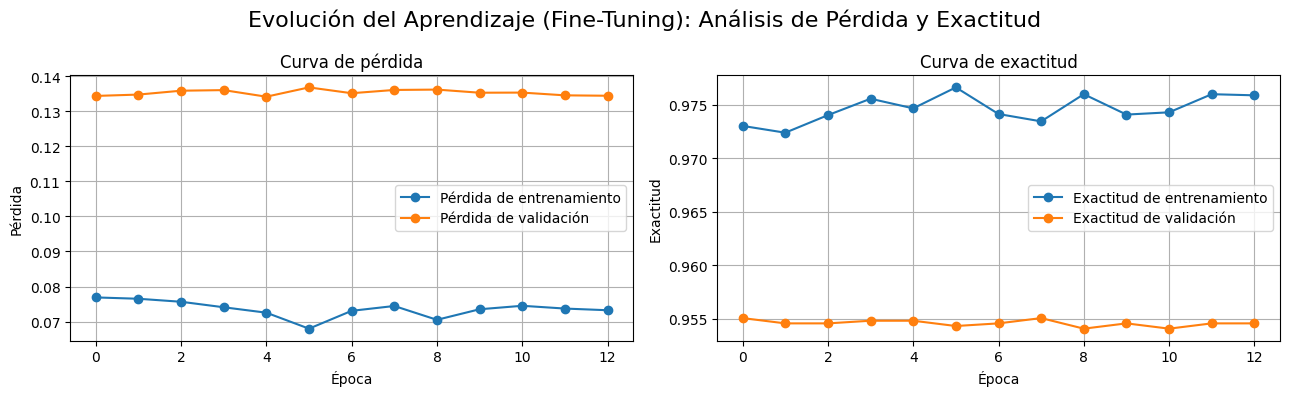

In [20]:
# Crear la figura y los subgráficos
fig, axs = plt.subplots(1, 2, figsize=(13, 4))

# Título general de la figura
fig.suptitle('Evolución del Aprendizaje (Fine-Tuning): Análisis de Pérdida y Exactitud', fontsize=16)

# Primer gráfico: Pérdida
axs[0].plot(historial_ft_dict['loss'], 'o-', label='Pérdida de entrenamiento')
axs[0].plot(historial_ft_dict['val_loss'], 'o-', label='Pérdida de validación')
axs[0].set_xlabel('Época')
axs[0].set_ylabel('Pérdida')
axs[0].set_title('Curva de pérdida')
axs[0].legend()
axs[0].grid(True)

# Segundo gráfico: Exactitud
axs[1].plot(historial_ft_dict['accuracy'], 'o-', label='Exactitud de entrenamiento')
axs[1].plot(historial_ft_dict['val_accuracy'], 'o-', label='Exactitud de validación')
axs[1].set_xlabel('Época')
axs[1].set_ylabel('Exactitud')
axs[1].set_title('Curva de exactitud')
axs[1].legend()
axs[1].grid(True)

plt.tight_layout()
plt.show()

In [18]:
# 1. Guardar el modelo final de Fine-Tuning
ruta_modelo_final_ft = f'{BASE_DIR}/models/fine_tuned/modelo_efnetb0_ft_final.keras'
model_tl.save(ruta_modelo_final_ft)
print(f"✅ Modelo final de Fine-Tuning guardado exitosamente en:\n{ruta_modelo_final_ft}\n")

# 2. Guardar el historial de Fine-Tuning
ruta_historial_ft = f'{BASE_DIR}/logs/histories/historial_ft_efficientnet.json'
try:
    historial_ft_dict = history_ft.history.copy()
    for key in historial_ft_dict.keys():
        historial_ft_dict[key] = [float(val) for val in historial_ft_dict[key]]

    with open(ruta_historial_ft, 'w') as f:
        json.dump(historial_ft_dict, f, indent=4)
    print(f"✅ Historial de Fine-Tuning guardado automáticamente en:\n{ruta_historial_ft}")
except Exception as e:
    print(f"⚠️ Error al guardar el historial de Fine-Tuning: {e}")

✅ Modelo final de Fine-Tuning guardado exitosamente en:
/content/drive/MyDrive/ClasificacionTerreno/models/fine_tuned/modelo_efnetb0_ft_final.keras

✅ Historial de Fine-Tuning guardado automáticamente en:
/content/drive/MyDrive/ClasificacionTerreno/logs/histories/historial_ft_efficientnet.json


### **COMPARACIÓN DEFINITIVA: CNN Base vs Transfer Learning (Completo)**

A continuación, visualizamos el panorama completo: el rendimiento de nuestra CNN original construida desde cero frente al ciclo completo de Transfer Learning (Extracción de Características + Fine-Tuning).

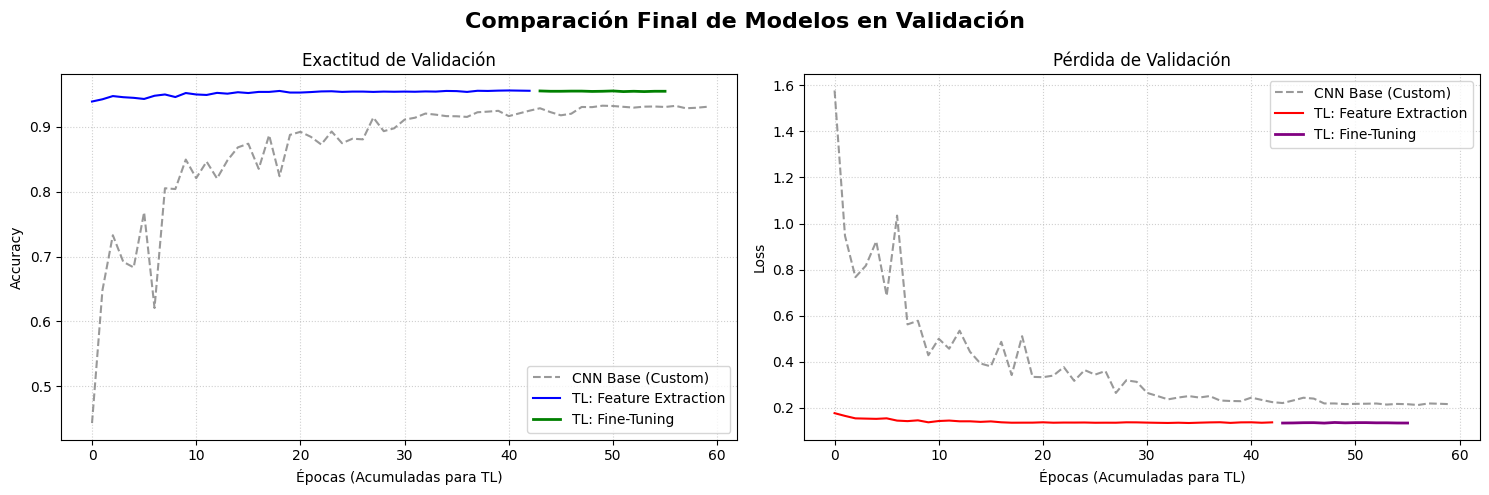


RESUMEN DEFINITIVO EN CONJUNTO DE PRUEBA (TEST)
- Métrica -        | - CNN Base (Custom) - | - TL (Feature Extraction) - | - TL (Fine-Tuning) -
-------------------------------------------------------------------------------------
- Exactitud -      | 0.9304               | 0.9573                    | 0.9573
- Pérdida -        | 0.2096               | 0.1391                    | 0.1377


In [30]:
ruta_historial_cnn = os.path.join(BASE_DIR, 'logs/histories/historial_cnn_base.json')
ruta_historial_tl = os.path.join(BASE_DIR, 'logs/histories/historial_tl_efficientnet.json')
ruta_historial_ft = os.path.join(BASE_DIR, 'logs/histories/historial_ft_efficientnet.json')

historial_cnn, historial_tl, historial_ft = None, None, None

# Cargar los historiales
if os.path.exists(ruta_historial_cnn):
    with open(ruta_historial_cnn, 'r') as f: historial_cnn = json.load(f)
if os.path.exists(ruta_historial_tl):
    with open(ruta_historial_tl, 'r') as f: historial_tl = json.load(f)
if os.path.exists(ruta_historial_ft):
    with open(ruta_historial_ft, 'r') as f: historial_ft = json.load(f)

fig, axs = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Comparación Final de Modelos en Validación', fontsize=16, fontweight='bold')

# --- Gráfico 1: Exactitud (Accuracy) ---
if historial_cnn:
    axs[0].plot(historial_cnn['val_accuracy'], label='CNN Base (Custom)', linestyle='--', color='gray', alpha=0.8)
if historial_tl:
    axs[0].plot(historial_tl['val_accuracy'], label='TL: Feature Extraction', color='blue')
if historial_ft:
    # Desplazamos el Fine-Tuning para que empiece donde terminó el Feature Extraction
    epocas_tl = len(historial_tl['val_accuracy']) if historial_tl else 0
    axs[0].plot(range(epocas_tl, epocas_tl + len(historial_ft['val_accuracy'])),
                historial_ft['val_accuracy'], label='TL: Fine-Tuning', color='green', linewidth=2)

axs[0].set_title('Exactitud de Validación')
axs[0].set_xlabel('Épocas (Acumuladas para TL)')
axs[0].set_ylabel('Accuracy')
axs[0].legend()
axs[0].grid(True, linestyle=':', alpha=0.6)

# --- Gráfico 2: Pérdida (Loss) ---
if historial_cnn:
    axs[1].plot(historial_cnn['val_loss'], label='CNN Base (Custom)', linestyle='--', color='gray', alpha=0.8)
if historial_tl:
    axs[1].plot(historial_tl['val_loss'], label='TL: Feature Extraction', color='red')
if historial_ft:
    epocas_tl = len(historial_tl['val_loss']) if historial_tl else 0
    axs[1].plot(range(epocas_tl, epocas_tl + len(historial_ft['val_loss'])),
                historial_ft['val_loss'], label='TL: Fine-Tuning', color='purple', linewidth=2)

axs[1].set_title('Pérdida de Validación')
axs[1].set_xlabel('Épocas (Acumuladas para TL)')
axs[1].set_ylabel('Loss')
axs[1].legend()
axs[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# --- Tabla Resumen Final en Test ---
print("\n\033[1mRESUMEN DEFINITIVO EN CONJUNTO DE PRUEBA (TEST)\033[0m")
print("=" * 85)
print(f"{'- Métrica -':<18} | {'- CNN Base (Custom) -':<20} | {'- TL (Feature Extraction) -':<25} | {'- TL (Fine-Tuning) -'}")
print("-" * 85)

acc_cnn = score[1] if 'score' in globals() else None
acc_tl = score_tl[1] if 'score_tl' in globals() else None
acc_ft = score_ft[1] if 'score_ft' in globals() else None

loss_cnn = score[0] if 'score' in globals() else None
loss_tl = score_tl[0] if 'score_tl' in globals() else None
loss_ft = score_ft[0] if 'score_ft' in globals() else None

str_acc_cnn = f"{acc_cnn:.4f}" if acc_cnn is not None else "N/A"
str_acc_tl  = f"{acc_tl:.4f}" if acc_tl is not None else "N/A"
str_acc_ft  = f"{acc_ft:.4f}" if acc_ft is not None else "N/A"

str_loss_cnn = f"{loss_cnn:.4f}" if loss_cnn is not None else "N/A"
str_loss_tl  = f"{loss_tl:.4f}" if loss_tl is not None else "N/A"
str_loss_ft  = f"{loss_ft:.4f}" if loss_ft is not None else "N/A"

print(f"{'- Exactitud -':<18} | {str_acc_cnn:<20} | {str_acc_tl:<25} | {str_acc_ft}")
print(f"{'- Pérdida -':<18} | {str_loss_cnn:<20} | {str_loss_tl:<25} | {str_loss_ft}")
print("=" * 85)

### **08. CONCLUSIONES FINALES Y TRABAJO FUTURO**

El desarrollo de este sistema de clasificación de imágenes satelitales (EuroSAT) ha demostrado la evolución y el impacto directo que tienen las diferentes arquitecturas de Redes Neuronales Convolucionales (CNN) sobre el rendimiento predictivo. A partir de los experimentos realizados, se extraen las siguientes conclusiones definitivas:

1. **Validación de la Arquitectura Base (Baseline Sólido):**
   La construcción de una red neuronal CNN profunda y optimizada desde cero (Custom CNN) logró un excelente rendimiento del **93.04%** en el conjunto de prueba. Esto confirmó la eficacia del diseño de 3 bloques convolucionales, el balance correcto de la regularización (Dropout y Batch Normalization) y una convergencia de aprendizaje estable y libre de un sobreajuste severo.

2. **Superación del Cuello de Botella Visual mediante Transfer Learning:**
   El análisis de la CNN base reveló dificultades algorítmicas para diferenciar microtexturas agrícolas y naturales de grano fino (ej. *HerbaceousVegetation* vs *PermanentCrop*). Al implementar **Transfer Learning** con la arquitectura preentrenada **EfficientNetB0** (Fase de Feature Extraction), la capacidad del modelo para extraer estas texturas jerárquicas aumentó drásticamente, elevando la exactitud a **95.73%** y reduciendo la pérdida a **0.139**.

3. **Maximización del Rendimiento a través del Fine-Tuning:**
   El paso final de descongelar los filtros convolucionales del modelo base (Fine-Tuning) y entrenarlos con una tasa de aprendizaje sumamente reducida ($1\times 10^{-5}$) representó el punto álgido del proyecto. El modelo logró adaptarse íntimamente a las geometrías del dominio satelital, manteniendo la métrica final estable en un **95.73%** de exactitud y minimizando la función de pérdida a **0.138**, lo que se traduce en un sistema altamente robusto y confiable.

**Trabajo Futuro y Aplicaciones:**
* **Despliegue en Producción:** El modelo final (Fine-Tuning) está matemáticamente consolidado y listo para ser exportado a un entorno de inferencia (vía API, servidor o *Edge Computing*) para analizar de forma continua grandes volúmenes de terreno.
* **Ensamble de Modelos (*Ensemble Methods*):** Para intentar llevar la exactitud por encima del 98%, se podrían combinar las predicciones probabilísticas del EfficientNetB0 con arquitecturas alternativas como Vision Transformers (ViT).
* **Análisis de Bandas Multiespectrales:** Dado que el satélite Sentinel-2 posee más de 3 canales (13 bandas multiespectrales en total), futuras iteraciones del modelo podrían entrenarse utilizando el espectro infrarrojo (NIR) para detectar con aún mayor precisión la salud y tipo de la vegetación (índices NDVI).